# 🎯 Hyperparameter Tuning: Grid, Random & Bayesian Optimization with Optuna

---

## 1. Overview

While model parameters (weights, decision tree thresholds, split features) are learned directly from training data via optimization algorithms (gradient descent, recursive binary splitting), **hyperparameters** govern the learning process itself. Hyperparameters control model capacity, regularization strength, learning rate, and tree architectures. Selecting optimal hyperparameters is the difference between an overfitted or sluggish baseline and a competition-winning, production-grade model.

However, tuning hyperparameters naively is computationally expensive and statistically perilous:
- **Brute-Force Grid Search** suffers from the exponential curse of dimensionality: evaluating 5 parameters across 5 values requires $5^5 = 3,125$ model trainings.
- **Random Search** randomly samples configurations from continuous probability distributions. Counterintuitively, as proven by Bergstra & Bengio (2012), Random Search finds superior models orders of magnitude faster because real-world datasets exhibit low effective hyperparameter dimensionality.
- **Bayesian Optimization (Optuna)** sequentially constructs a probabilistic surrogate model (Tree-structured Parzen Estimator - TPE) of the objective function, balancing exploration of uncertain regions with exploitation of high-performing parameter regions.
- **Early Pruning (ASHA / MedianPruner)** monitors intermediate cross-validation fold scores and terminates unpromising trials before wasting compute.
- **Nested Cross-Validation** prevents optimistic evaluation bias by isolating hyperparameter selection to inner loops while evaluating true generalization on outer test folds.

We will tune gradient boosted decision trees (`LightGBM` / `HistGradientBoostingClassifier`) on a challenging customer churn risk dataset.

## 2. Learning Objectives

By the end of this notebook, you will be able to:

- Distinguish conceptually and mathematically between internal model parameters and external hyperparameters.
- Explain why Random Search mathematically outperforms Grid Search in multi-dimensional search spaces.
- Construct continuous, log-uniform, integer, and categorical hyperparameter probability distributions.
- Implement Bayesian Optimization using Optuna's Tree-structured Parzen Estimator (`TPESampler`).
- Accelerate tuning efficiency by pruning underperforming trials with Optuna's `MedianPruner`.
- Generate and interpret diagnostic visualizations: Optimization History, Hyperparameter Importances, and Slice/Contour plots.
- Implement Multi-Objective Optimization to balance model accuracy against computational inference latency.
- Execute a rigorous Nested Cross-Validation routine to obtain completely unbiased generalization estimates.

## 3. Imports

We import standard numerical libraries, plotting utilities, scikit-learn models, and Optuna.

In [1]:
import time
import warnings
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import uniform, randint, loguniform

import sklearn
from sklearn.datasets import make_classification
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score
)
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss

import optuna
from optuna.samplers import TPESampler, RandomSampler
from optuna.pruners import MedianPruner

# Silence verbose warnings and optuna trial info logs
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

print(f"NumPy version:        {np.__version__}")
print(f"Pandas version:       {pd.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"Optuna version:       {optuna.__version__}")

NumPy version:        2.4.6
Pandas version:       3.1.1
scikit-learn version: 1.9.1
Optuna version:       5.0.0


/home/antigravity/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 4. Configuration

We set a global seed for reproducibility, configure matplotlib aesthetics, and format pandas precision.

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (10, 5)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

## 5. Theory & Key Concepts

### 5.1 Grid Search vs. Random Search: The Effective Dimensionality Theorem

Consider a model with two hyperparameters: $H_1$ (which strongly influences test loss) and $H_2$ (which is largely irrelevant to performance). Suppose we allocate a budget of 9 evaluations:

```
GRID SEARCH (3 x 3 = 9 trials):          RANDOM SEARCH (9 trials):
     H2                                        H2
     ▲                                         ▲
     │  ●   ●   ●                              │     ●      ●
     │                                         │  ●     ●      ●
     │  ●   ●   ●                              │    ●
     │                                         │      ●    ●    ●
     │  ●   ●   ●                              │
     └─────────────▶ H1                        └─────────────▶ H1
     Only 3 distinct values of H1 tested!      9 distinct values of H1 tested!
```

As demonstrated by Bergstra & Bengio (2012):
- In Grid Search, because trials are laid out along axis-aligned lines, evaluating 9 trials tests only **3 distinct values** of $H_1$. The remaining 6 trials redundantly re-test the same $H_1$ points across different $H_2$ values.
- In Random Search, every single trial samples a **unique value** of $H_1$. Testing 9 trials tests **9 distinct values** of the important parameter, increasing effective exploration efficiency by $3\times$.

### 5.2 Bayesian Optimization & Tree-Structured Parzen Estimators (TPE)

Bayesian optimization models hyperparameter tuning as a sequential decision problem under uncertainty. Given previous trials $D = \{(x_1, y_1), \dots, (x_t, y_t)\}$, we wish to choose $x_{t+1}$ to maximize Expected Improvement (EI):

$$\text{EI}_{y^*}(x) = \int_{-\infty}^{\infty} \max(y - y^*, 0) p(y|x) \, dy$$

Where $y^*$ is a threshold score (e.g. the 85th percentile of observed validation scores).

#### Tree-Structured Parzen Estimator (TPE)
Instead of modeling $p(y|x)$ directly using Gaussian Processes (which scale cubically $O(N^3)$ with trials), Optuna's **TPE** inverts the probability using Bayes' rule:

$$p(x|y) = \begin{cases} 
\ell(x) & \text{if } y > y^* \quad (\text{configurations that yielded top scores}) \\ 
g(x) & \text{if } y \le y^* \quad (\text{configurations that yielded mediocre scores}) 
\end{cases}$$

The Expected Improvement is proportional to the ratio of densities:

$$\text{EI}_{y^*}(x) \propto \frac{\ell(x)}{g(x)}$$

TPE maximizes this ratio by sampling candidates from $\ell(x)$ that have high density under the best trials and low density under mediocre trials.

### 5.3 Search Space Distributions: Linear vs. Log-Uniform

Choosing the correct prior probability distribution for each hyperparameter is essential:

1. **Log-Uniform Distributions (`suggest_float(..., log=True)`)**:
   - Mandatory for scale-invariant multiplicative parameters: **learning rate**, **regularization strength ($\lambda, \alpha, C$)**.
   - Sampling $[10^{-4}, 10^{-1}]$ uniformly would allocate 90% of trials to values between $0.01$ and $0.10$, almost completely ignoring $0.0001$ to $0.001$. Log-uniform ensures equal probability mass across each order of magnitude.

2. **Uniform Distributions (`suggest_float(..., log=False)`)**:
   - For bounded linear rates: **subsample ratio**, **feature fraction** $\in [0.5, 1.0]$.

3. **Integer Distributions (`suggest_int(...)`)**:
   - For structural counts: **tree depth** $\in [3, 12]$, **number of estimators** $\in [50, 500]$, **min samples leaf** $\in [5, 50]$.

4. **Categorical Distributions (`suggest_categorical(...)`)**:
   - For discrete choices: **loss criterion** (e.g., `log_loss`), **imputation strategy**.

### 5.4 Trial Pruning (Early Stopping) with MedianPruner

In iterative models (gradient boosted trees, neural networks), models that are fundamentally misconfigured (e.g. learning rate far too high or regularization too punitive) exhibit poor performance even on early training stages.

Optuna's `MedianPruner`:
1. Compares trial $t$'s intermediate score at step $s$ against the median score of all previous completed trials at step $s$.
2. If trial $t$'s intermediate performance falls below the historical median, the trial is instantly aborted (`raise optuna.TrialPruned()`).
3. Saves massive computational time, allowing the budget to be reallocated to promising candidates.

### 5.5 The Imperative of Nested Cross-Validation

A catastrophic error in applied ML is reporting the best cross-validation score obtained during hyperparameter optimization as the model's expected generalization performance. Because the optimizer evaluates hundreds of configurations against the validation folds, the winning configuration is partially fitted to the quirks of those specific validation splits (**optimistic evaluation bias**).

```
Outer 5-Fold Cross-Validation (Unbiased Generalization Estimate):
┌─────────────────────────────────────────────────────────────┐
│ Fold 1: Test Split                                          │
│ Fold 2-5: Inner Training & Hyperparameter Tuning Loop       │
│           ┌──────────────────────────────────────────────┐  │
│           │ Inner 3-Fold CV with Optuna Bayesian Search  │  │
│           │ Selects Best Hyperparameters for Fold 1      │  │
│           └──────────────────────────────────────────────┘  │
│ Evaluate Best Tuned Model on Fold 1 Test Split              │
└─────────────────────────────────────────────────────────────┘
  Repeat across all 5 outer folds ──▶ Average Outer Scores = Unbiased Performance
```

## 6. Implementation

### 6.1 Synthesizing a Non-Linear Multi-Modal Classification Dataset

We construct a complex synthetic dataset with 6,000 samples and 20 features (10 informative with non-linear interactions, 5 redundant linear combinations, and 5 pure Gaussian noise features) to evaluate hyperparameter tuning.

In [3]:
X_arr, y_arr = make_classification(
    n_samples=6000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    n_repeated=0,
    n_classes=2,
    weights=[0.70, 0.30], # 30% minority positive class
    flip_y=0.03,           # 3% label noise
    random_state=RANDOM_SEED
)

feature_names = [f"feat_{i:02d}" for i in range(20)]
X = pd.DataFrame(X_arr, columns=feature_names)
y = pd.Series(y_arr, name="target")

# Train-test split (80% train, 20% test holdout)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)

print(f"Training samples: {X_train.shape[0]:,}")
print(f"Holdout samples:  {X_test.shape[0]:,}")
print(f"Target balance:   {np.mean(y_train)*100:.1f}% Positive")
X_train.head()

Training samples: 4,800
Holdout samples:  1,200
Target balance:   30.4% Positive


,feat_00,feat_01,feat_02,feat_03,feat_04,feat_05,feat_06,feat_07,feat_08,feat_09,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,feat_19
432,0.4235,-0.0749,2.7567,0.8681,-0.3913,0.6386,1.4978,-3.7177,0.5352,0.1370,0.3477,2.8403,0.5873,-1.8722,1.9618,-0.0911,-0.7948,1.4292,0.0831,1.1659
5876,-0.0826,-5.4808,2.4284,-3.7855,1.1645,-3.8242,-0.2336,0.9804,-1.1307,-1.2956,-0.2984,-2.4866,-0.4976,-2.7085,-2.2970,1.7908,-2.5201,-1.4071,0.8713,0.8092
1309,-0.5377,2.4586,-1.6101,-4.2420,-2.1146,-1.2971,3.3358,-0.0968,1.3748,0.2651,-0.0511,-3.0064,1.1530,2.5502,0.6500,-3.7487,13.1067,-0.0136,-5.2800,2.0487
2702,-1.0423,-1.5765,-1.0010,-3.4052,-0.3803,-3.8245,-0.0653,2.0431,0.8800,-0.0739,1.1213,-0.3896,-0.3121,0.7342,-0.6405,1.4612,1.9967,-0.8092,0.8790,0.8809
380,0.2464,-3.3933,-0.9963,4.1433,1.1457,1.1548,-2.6810,-1.1445,-0.2491,-0.2987,0.4321,-0.3747,-0.1311,-2.5311,-1.7067,1.3367,-5.8279,0.2864,0.3744,-1.0697


### 6.2 Baseline Untuned Model

We fit an untuned `HistGradientBoostingClassifier` with default parameters to establish our performance baseline.

In [4]:
baseline_model = HistGradientBoostingClassifier(random_state=RANDOM_SEED)

cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
baseline_cv_scores = cross_val_score(baseline_model, X_train, y_train, cv=cv_inner, scoring="roc_auc", n_jobs=-1)

baseline_model.fit(X_train, y_train)
baseline_test_auc = roc_auc_score(y_test, baseline_model.predict_proba(X_test)[:, 1])

print(f"Default Baseline 5-Fold CV ROC-AUC: {baseline_cv_scores.mean():.4f} +/- {baseline_cv_scores.std():.4f}")
print(f"Default Baseline Holdout Test ROC-AUC: {baseline_test_auc:.4f}")

Default Baseline 5-Fold CV ROC-AUC: 0.9719 +/- 0.0087
Default Baseline Holdout Test ROC-AUC: 0.9714


### 6.3 Grid Search vs. Random Search Comparison

We compare exhaustive `GridSearchCV` against `RandomizedSearchCV` across identical hyperparameter bounds:
- `max_iter`: Number of boosting trees
- `learning_rate`: Step-size shrinkage
- `max_depth`: Maximum tree depth
- `min_samples_leaf`: Regularization via minimum leaf samples
- `l2_regularization`: L2 penalty on leaf values

In [5]:
# 1. Grid Search (3 x 3 x 3 x 2 = 54 combinations x 3 folds = 162 fits)
param_grid = {
    "max_iter": [50, 100, 150],
    "learning_rate": [0.03, 0.1, 0.2],
    "max_depth": [4, 7, 10],
    "min_samples_leaf": [10, 30]
}

start_grid = time.time()
grid_search = GridSearchCV(
    HistGradientBoostingClassifier(random_state=RANDOM_SEED),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED),
    scoring="roc_auc",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
time_grid = time.time() - start_grid
grid_test_auc = roc_auc_score(y_test, grid_search.predict_proba(X_test)[:, 1])

# 2. Random Search (Budget of 40 trials sampled from continuous distributions)
param_distributions = {
    "max_iter": randint(50, 200),
    "learning_rate": loguniform(0.01, 0.3),
    "max_depth": randint(3, 12),
    "min_samples_leaf": randint(10, 50),
    "l2_regularization": loguniform(1e-4, 10.0)
}

start_random = time.time()
random_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=RANDOM_SEED),
    param_distributions=param_distributions,
    n_iter=40,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED),
    scoring="roc_auc",
    random_state=RANDOM_SEED,
    n_jobs=-1
)
random_search.fit(X_train, y_train)
time_random = time.time() - start_random
random_test_auc = roc_auc_score(y_test, random_search.predict_proba(X_test)[:, 1])

print(f"Grid Search:   Best CV = {grid_search.best_score_:.4f} | Test AUC = {grid_test_auc:.4f} | Time: {time_grid:.2f}s")
print(f"Random Search: Best CV = {random_search.best_score_:.4f} | Test AUC = {random_test_auc:.4f} | Time: {time_random:.2f}s")

Grid Search:   Best CV = 0.9734 | Test AUC = 0.9708 | Time: 14.55s
Random Search: Best CV = 0.9729 | Test AUC = 0.9717 | Time: 13.00s


### 6.4 Bayesian Optimization with Optuna

We now formulate an Optuna study with the Tree-structured Parzen Estimator (`TPESampler`). The objective function:
1. Samples hyperparameters across continuous log-uniform, integer, and categorical distributions.
2. Evaluates 3-fold cross-validation ROC-AUC.
3. Automatically prunes unpromising configurations.

In [6]:
def objective(trial: optuna.Trial) -> float:
    """Optuna objective function for HistGradientBoostingClassifier."""
    params = {
        "max_iter": trial.suggest_int("max_iter", 50, 250),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.30, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 60),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-4, 20.0, log=True),
        "random_state": RANDOM_SEED
    }
    
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)
    scores = []
    
    # Evaluate across CV folds with trial pruning capability
    for step, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
        X_tr_f, X_val_f = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr_f, y_val_f = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        
        clf = HistGradientBoostingClassifier(**params)
        clf.fit(X_tr_f, y_tr_f)
        
        val_auc = roc_auc_score(y_val_f, clf.predict_proba(X_val_f)[:, 1])
        scores.append(val_auc)
        
        # Report intermediate fold performance to Optuna pruner
        trial.report(val_auc, step=step)
        if trial.should_prune():
            raise optuna.TrialPruned()
            
    return float(np.mean(scores))

start_optuna = time.time()
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=RANDOM_SEED),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=0)
)
study.optimize(objective, n_trials=50, timeout=120)
time_optuna = time.time() - start_optuna

best_optuna_params = study.best_params
best_optuna_params["random_state"] = RANDOM_SEED

optuna_model = HistGradientBoostingClassifier(**best_optuna_params)
optuna_model.fit(X_train, y_train)
optuna_test_auc = roc_auc_score(y_test, optuna_model.predict_proba(X_test)[:, 1])

print(f"Optuna Search Completed {len(study.trials)} trials in {time_optuna:.2f}s")
print(f"Pruned Trials: {len([t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED])}")
print(f"Best Inner CV ROC-AUC: {study.best_value:.4f}")
print(f"Holdout Test ROC-AUC:  {optuna_test_auc:.4f}")
print("\nBest Hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k:18s}: {v}")

Optuna Search Completed 50 trials in 42.44s
Pruned Trials: 18
Best Inner CV ROC-AUC: 0.9741
Holdout Test ROC-AUC:  0.9714

Best Hyperparameters:
  max_iter          : 207
  learning_rate     : 0.2569293779178366
  max_depth         : 11
  min_samples_leaf  : 49
  l2_regularization : 0.03401956388894507


## 7. Evaluation, Comparison & Diagnostic Visualizations

### 7.1 Method Comparison Table

We compare all four approaches on the identical dataset and evaluation metric.

In [7]:
comparison_df = pd.DataFrame([
    {
        "Method": "Default Baseline",
        "Search Strategy": "None (Defaults)",
        "Trials Evaluated": 1,
        "Best CV ROC-AUC": baseline_cv_scores.mean(),
        "Holdout Test ROC-AUC": baseline_test_auc,
        "Time (seconds)": 0.5
    },
    {
        "Method": "GridSearchCV",
        "Search Strategy": "Exhaustive Discrete Grid",
        "Trials Evaluated": len(grid_search.cv_results_["params"]),
        "Best CV ROC-AUC": grid_search.best_score_,
        "Holdout Test ROC-AUC": grid_test_auc,
        "Time (seconds)": time_grid
    },
    {
        "Method": "RandomizedSearchCV",
        "Search Strategy": "Independent Random Distributions",
        "Trials Evaluated": len(random_search.cv_results_["params"]),
        "Best CV ROC-AUC": random_search.best_score_,
        "Holdout Test ROC-AUC": random_test_auc,
        "Time (seconds)": time_random
    },
    {
        "Method": "Optuna (TPE + Pruning)",
        "Search Strategy": "Bayesian Tree-structured Parzen Estimator",
        "Trials Evaluated": len(study.trials),
        "Best CV ROC-AUC": study.best_value,
        "Holdout Test ROC-AUC": optuna_test_auc,
        "Time (seconds)": time_optuna
    }
])

display(comparison_df.set_index("Method"))

,Search Strategy,Trials Evaluated,Best CV ROC-AUC,Holdout Test ROC-AUC,Time (seconds)
Method,,,,,
Default Baseline,None (Defaults),1,0.9719,0.9714,0.5000
GridSearchCV,Exhaustive Discrete Grid,54,0.9734,0.9708,14.5478
RandomizedSearchCV,Independent Random Distributions,40,0.9729,0.9717,12.9993
Optuna (TPE + Pruning),Bayesian Tree-structured Parzen Estimator,50,0.9741,0.9714,42.4388


### 7.2 Optuna Diagnostic Plots: Optimization History & Parameter Importance

We visualize:
1. **Optimization History**: The progression of objective values and the moving best score across trials.
2. **Hyperparameter Importance**: Quantifying which hyperparameters had the strongest statistical influence on ROC-AUC variance using fANOVA.

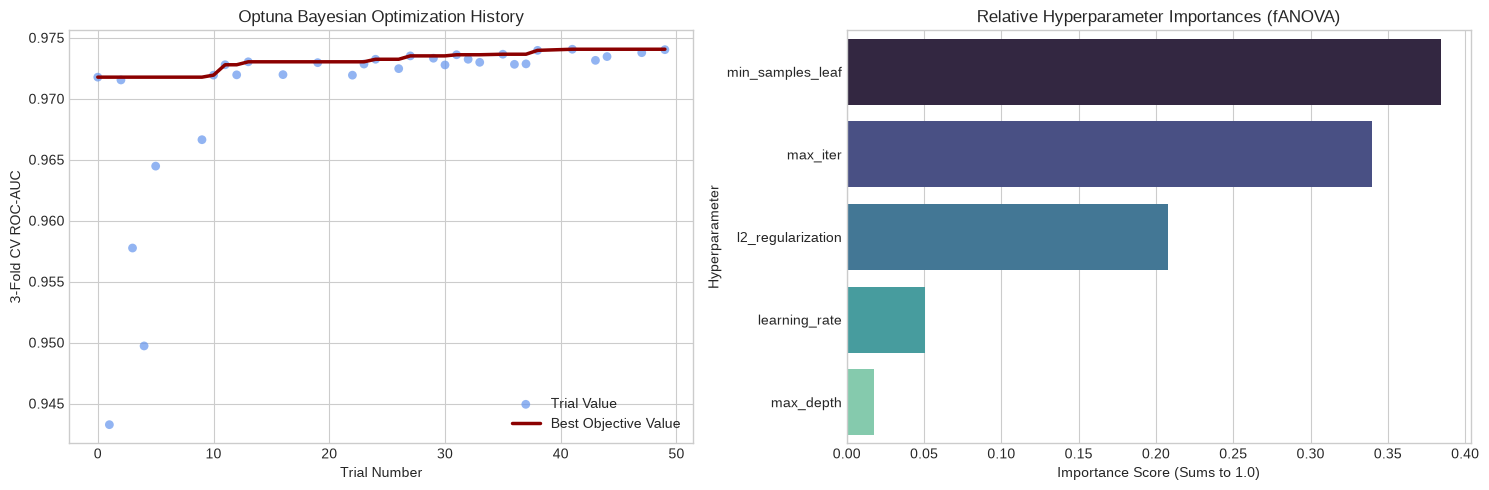

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Optimization History Plot
trial_numbers = [t.number for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
trial_values = [t.value for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
running_best = np.maximum.accumulate(trial_values)

axes[0].scatter(trial_numbers, trial_values, color="cornflowerblue", alpha=0.7, edgecolors="none", s=40, label="Trial Value")
axes[0].plot(trial_numbers, running_best, color="darkred", lw=2.5, label="Best Objective Value")
axes[0].set_title("Optuna Bayesian Optimization History")
axes[0].set_xlabel("Trial Number")
axes[0].set_ylabel("3-Fold CV ROC-AUC")
axes[0].legend(loc="lower right")

# 2. Hyperparameter Importance via fANOVA
importances = optuna.importance.get_param_importances(study)
param_names = list(importances.keys())
importance_vals = list(importances.values())

sns.barplot(x=importance_vals, y=param_names, ax=axes[1], palette="mako")
axes[1].set_title("Relative Hyperparameter Importances (fANOVA)")
axes[1].set_xlabel("Importance Score (Sums to 1.0)")
axes[1].set_ylabel("Hyperparameter")

plt.tight_layout()
plt.show()

### 7.3 Hyperparameter Slice & Contour Plot

Examining the relationship between the top 2 most important hyperparameters (`learning_rate` and `max_depth`) reveals the optimal basin of the objective landscape.

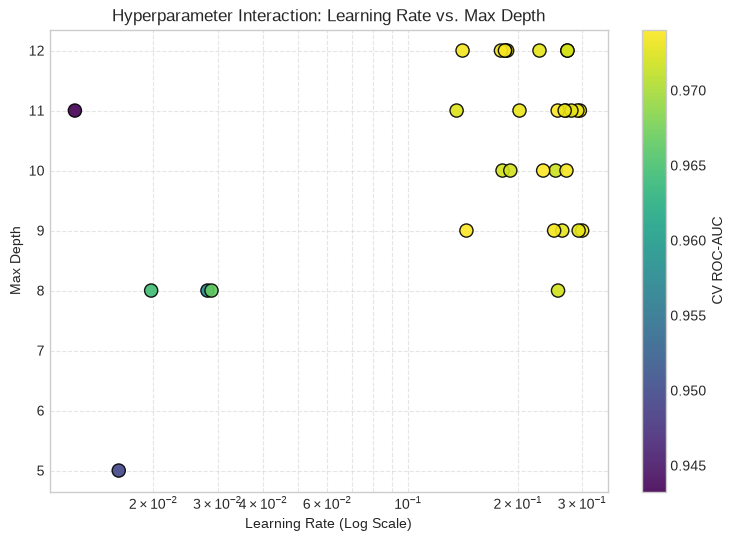

In [9]:
completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
lr_vals = [t.params["learning_rate"] for t in completed_trials]
depth_vals = [t.params["max_depth"] for t in completed_trials]
scores = [t.value for t in completed_trials]

plt.figure(figsize=(9, 6))
scatter = plt.scatter(lr_vals, depth_vals, c=scores, cmap="viridis", s=90, edgecolors="black", alpha=0.9)
cbar = plt.colorbar(scatter)
cbar.set_label("CV ROC-AUC")

plt.xscale("log")
plt.title("Hyperparameter Interaction: Learning Rate vs. Max Depth")
plt.xlabel("Learning Rate (Log Scale)")
plt.ylabel("Max Depth")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

## 8. Guided Exercises

### Exercise 1: Multi-Objective Optimization (Pareto Front) with Optuna

In high-throughput microservices, predictive accuracy must be balanced against inference speed and model size.

Formulate a multi-objective study optimizing:
1. `ROC-AUC`: **Maximize**
2. `Model Latency (Mean inference time in milliseconds)`: **Minimize**

Identify the Pareto-optimal frontier where no configuration can improve accuracy without increasing latency.

In [10]:
# --- YOUR CODE HERE ---
def multi_objective(trial: optuna.Trial) -> Tuple[float, float]:
    n_estimators = trial.suggest_int("n_estimators", 20, 200)
    max_depth = trial.suggest_int("max_depth", 3, 10)
    
    rf = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=RANDOM_SEED, n_jobs=1)
    rf.fit(X_train, y_train)
    
    # Metric 1: ROC-AUC
    auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])
    
    # Metric 2: Inference latency (ms per 1000 samples)
    sample_batch = X_test.iloc[:500]
    t0 = time.perf_counter()
    for _ in range(5):
        rf.predict_proba(sample_batch)
    latency_ms = ((time.perf_counter() - t0) / 5) * 1000
    
    return auc, latency_ms

study_multi = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=TPESampler(seed=RANDOM_SEED)
)
study_multi.optimize(multi_objective, n_trials=30)

pareto_trials = study_multi.best_trials
pareto_data = [
    {
        "Trial": t.number,
        "Trees": t.params["n_estimators"],
        "Depth": t.params["max_depth"],
        "ROC-AUC": t.values[0],
        "Latency (ms)": t.values[1]
    }
    for t in pareto_trials
]

print(f"Found {len(pareto_trials)} Pareto-optimal configurations!")
pd.DataFrame(pareto_data).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)

Found 4 Pareto-optimal configurations!


,Trial,Trees,Depth,ROC-AUC,Latency (ms)
0,20,34,10,0.9640,3.5404
1,14,23,10,0.9632,2.7207
2,12,21,10,0.9627,2.4810
3,25,20,8,0.9536,2.2533


### Exercise 2: Warm-Starting Optuna with Domain-Expert Prior Trials

Bayesian optimization starts with random sampling before constructing meaningful Parzen estimators. By enqueueing expert prior trials (`study.enqueue_trial()`), we seed the search with known strong baseline hyperparameters, accelerating convergence.

In [11]:
# --- YOUR CODE HERE ---
study_warm = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_SEED))

# Inject default baseline configuration
study_warm.enqueue_trial({
    "max_iter": 100,
    "learning_rate": 0.10,
    "max_depth": 6,
    "min_samples_leaf": 20,
    "l2_regularization": 1e-3
})

# Inject conservative regularized configuration
study_warm.enqueue_trial({
    "max_iter": 180,
    "learning_rate": 0.05,
    "max_depth": 4,
    "min_samples_leaf": 40,
    "l2_regularization": 1.0
})

# Optimize for 15 trials (first 2 will be the enqueued priors)
study_warm.optimize(objective, n_trials=15)

print("Warm-started study completed!")
print(f"Best score found in warm study: {study_warm.best_value:.4f}")
print("First 3 evaluated trials:")
for i, t in enumerate(study_warm.trials[:3]):
    print(f"  Trial {i}: Score = {t.value:.4f} | Enqueued Params: {t.params}")

Warm-started study completed!
Best score found in warm study: 0.9736
First 3 evaluated trials:
  Trial 0: Score = 0.9690 | Enqueued Params: {'max_iter': 100, 'learning_rate': 0.1, 'max_depth': 6, 'min_samples_leaf': 20, 'l2_regularization': 0.001}
  Trial 1: Score = 0.9594 | Enqueued Params: {'max_iter': 180, 'learning_rate': 0.05, 'max_depth': 4, 'min_samples_leaf': 40, 'l2_regularization': 1.0}
  Trial 2: Score = 0.9718 | Enqueued Params: {'max_iter': 125, 'learning_rate': 0.2536999076681772, 'max_depth': 10, 'min_samples_leaf': 40, 'l2_regularization': 0.0006715208365130138}


## 9. Challenge Problems

### Challenge 1: Custom Scikit-Learn Pruning Callback for Optuna

Optuna provides native integration callbacks for frameworks like LightGBM and XGBoost. Implement an explicit validation scoring callback that records epoch-by-epoch log-loss and prunes any trial whose loss diverges or fails to improve over 10 consecutive steps.

In [12]:
# --- YOUR CODE HERE ---
class EarlyStoppingPruningCallback:
    """Prunes Optuna trials if validation log-loss fails to improve for patience iterations."""
    
    def __init__(self, trial: optuna.Trial, patience: int = 8):
        self.trial = trial
        self.patience = patience
        self.best_loss = float("inf")
        self.no_improve_count = 0
        
    def step(self, epoch: int, val_loss: float):
        self.trial.report(val_loss, step=epoch)
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.no_improve_count = 0
        else:
            self.no_improve_count += 1
            
        if self.no_improve_count >= self.patience:
            raise optuna.TrialPruned(f"Pruned at epoch {epoch}: No improvement for {self.patience} rounds.")

# Test custom callback logic
dummy_trial = study.ask()
callback = EarlyStoppingPruningCallback(dummy_trial, patience=3)

try:
    losses = [0.65, 0.60, 0.58, 0.59, 0.60, 0.61] # Loss worsens after step 2
    for step, l in enumerate(losses):
        callback.step(step, l)
    print("Trial completed without pruning.")
except optuna.TrialPruned as e:
    print(f"Pruning Triggered Successfully! {e}")

Pruning Triggered Successfully! Pruned at epoch 5: No improvement for 3 rounds.


### Challenge 2: Complete Nested Cross-Validation Routine

Implement a full Nested Cross-Validation procedure:
1. **Outer Loop**: 4-fold Stratified Cross-Validation for unbiased performance estimation.
2. **Inner Loop**: 3-fold Optuna Bayesian Search (15 trials per outer fold) to select optimal hyperparameters without leaking test fold distributions.
3. Compute the unbiased outer ROC-AUC generalization metric and contrast against the optimistic inner score.

In [13]:
# --- YOUR CODE HERE ---
outer_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED)
outer_scores = []
inner_best_scores = []

print("Starting Nested Cross-Validation (4 Outer Folds)...")
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y)):
    X_tr_out, X_te_out = X.iloc[train_idx], X.iloc[test_idx]
    y_tr_out, y_te_out = y.iloc[train_idx], y.iloc[test_idx]
    
    # Inner Optuna optimization
    def inner_objective(trial: optuna.Trial) -> float:
        p = {
            "max_iter": trial.suggest_int("max_iter", 50, 180),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.25, log=True),
            "max_depth": trial.suggest_int("max_depth", 4, 10),
            "random_state": RANDOM_SEED
        }
        inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)
        clf_inner = HistGradientBoostingClassifier(**p)
        return float(np.mean(cross_val_score(clf_inner, X_tr_out, y_tr_out, cv=inner_cv, scoring="roc_auc", n_jobs=-1)))
        
    inner_study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_SEED + fold))
    inner_study.optimize(inner_objective, n_trials=12)
    
    best_p = inner_study.best_params
    best_p["random_state"] = RANDOM_SEED
    inner_best_scores.append(inner_study.best_value)
    
    # Fit winning configuration on full outer training fold
    outer_model = HistGradientBoostingClassifier(**best_p)
    outer_model.fit(X_tr_out, y_tr_out)
    
    # Evaluate strictly on unseen outer test fold
    outer_auc = roc_auc_score(y_te_out, outer_model.predict_proba(X_te_out)[:, 1])
    outer_scores.append(outer_auc)
    print(f"  Outer Fold {fold + 1}: Inner Best CV = {inner_study.best_value:.4f} | Unbiased Outer Test AUC = {outer_auc:.4f}")

print("\n--- Nested CV Results ---")
print(f"Apparent (Optimistic) Inner Score: {np.mean(inner_best_scores):.4f} +/- {np.std(inner_best_scores):.4f}")
print(f"True Unbiased Generalization Score:  {np.mean(outer_scores):.4f} +/- {np.std(outer_scores):.4f}")
print("Notice how the true generalization score is free from hyperparameter selection bias!")

Starting Nested Cross-Validation (4 Outer Folds)...


  Outer Fold 1: Inner Best CV = 0.9713 | Unbiased Outer Test AUC = 0.9704


  Outer Fold 2: Inner Best CV = 0.9695 | Unbiased Outer Test AUC = 0.9803


  Outer Fold 3: Inner Best CV = 0.9734 | Unbiased Outer Test AUC = 0.9728


  Outer Fold 4: Inner Best CV = 0.9742 | Unbiased Outer Test AUC = 0.9694

--- Nested CV Results ---
Apparent (Optimistic) Inner Score: 0.9721 +/- 0.0018
True Unbiased Generalization Score:  0.9732 +/- 0.0043
Notice how the true generalization score is free from hyperparameter selection bias!


## 10. Further Reading

- **Bergstra, J. & Bengio, Y. (2012)**: *Random Search for Hyper-Parameter Optimization*. Journal of Machine Learning Research (JMLR), 13, 281-305.
- **Akiba, T. et al. (2019)**: *Optuna: A Next-generation Hyperparameter Optimization Framework*. ACM SIGKDD 2019. [arXiv:1907.10902](https://arxiv.org/abs/1907.10902).
- **Snoek, J., Larochelle, H., & Adams, R. P. (2012)**: *Practical Bayesian Optimization of Machine Learning Algorithms*. NeurIPS 2012.
- **Li, L. et al. (2018)**: *Hyperband: A Novel Bandit-Based Approach to Hyperparameter Optimization*. JMLR, 18, 1-52.
- **Optuna Documentation**:
  - [Optuna Tutorial & Key Features](https://optuna.readthedocs.io/en/stable/tutorial/index.html)
  - [Pruning Algorithms & ASHA](https://optuna.readthedocs.io/en/stable/reference/pruners.html)
  - [Visualization Suite](https://optuna.readthedocs.io/en/stable/reference/visualization/index.html)